# clustering of fault lines aong the west coast

CRS: EPSG:4326
Number of points: 112898
Geometry types:
Point    112898
Name: count, dtype: int64

Bounds: [-179.99998854   18.90407264  179.98537655   70.7516985 ]


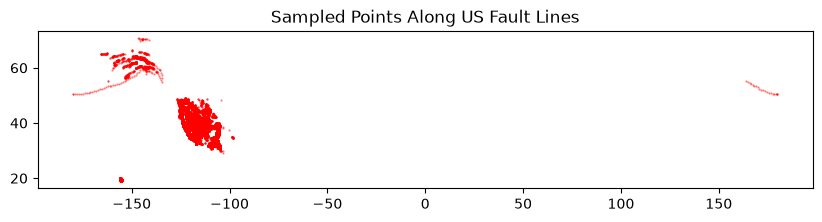

In [20]:
import geopandas as gpd
import matplotlib.pyplot as plt

fault_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs/Points along faults.shp"
)

faults = gpd.read_file(fault_path)

print("CRS:", faults.crs)
print("Number of points:", len(faults))
print("Geometry types:")
print(faults.geometry.geom_type.value_counts())
print("\nBounds:", faults.total_bounds)

# Display a quick preview
fig, ax = plt.subplots(figsize=(10, 8))

faults.plot(
    ax=ax,
    markersize=0.3,
    color="red",
    alpha=0.5
)

ax.set_title("Sampled Points Along US Fault Lines")
plt.show()

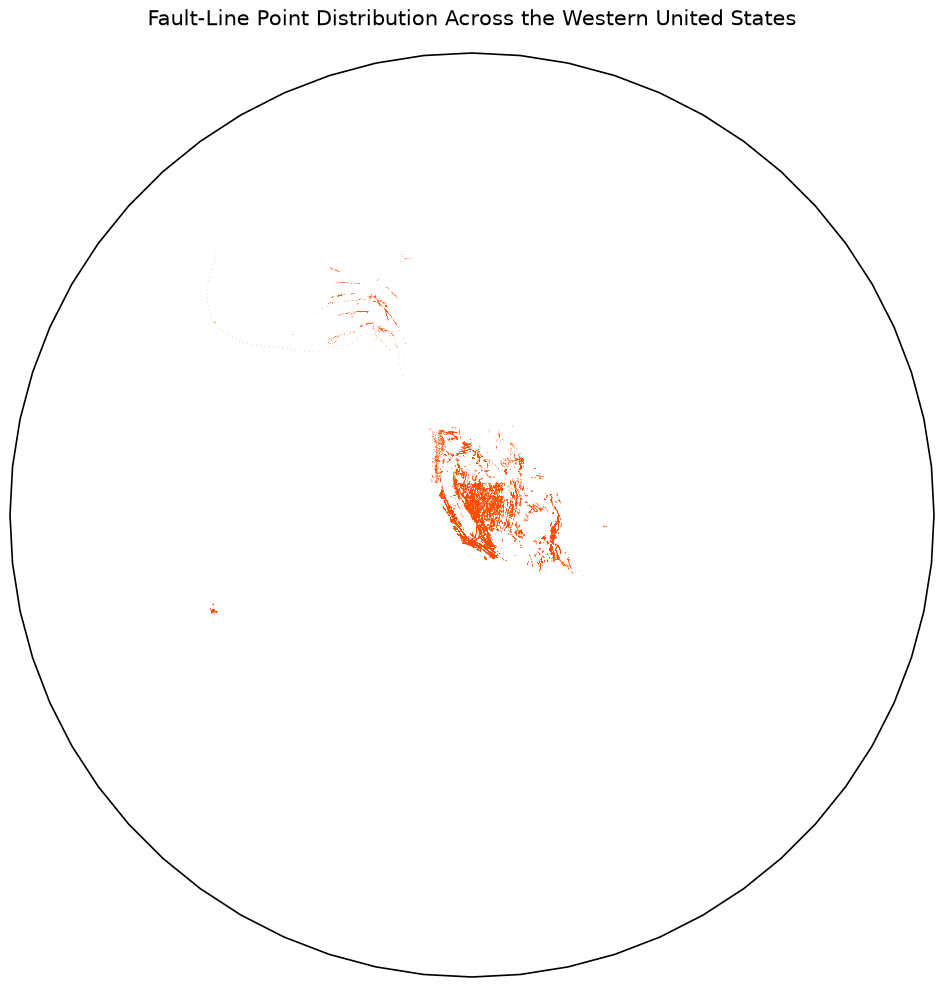

In [21]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fault_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs/Points along faults.shp"
)

faults = gpd.read_file(fault_path)

# Make sure the coordinates are longitude/latitude
faults = faults.to_crs("EPSG:4326")

# Globe-like projection centered on the western United States
ortho = ccrs.Orthographic(
    central_longitude=-119,
    central_latitude=38
)

fig = plt.figure(figsize=(12, 12))

ax = fig.add_subplot(
    1, 1, 1,
    projection=ortho
)

ax.set_global()

# Globe outline
ax.spines["geo"].set_linewidth(1.2)

# Plot the fault points
ax.scatter(
    faults.geometry.x,
    faults.geometry.y,
    transform=ccrs.PlateCarree(),
    s=0.15,
    color="#ff4d00",
    alpha=0.65,
    linewidths=0,
    rasterized=True
)

ax.set_title(
    "Fault-Line Point Distribution Across the Western United States",
    fontsize=15,
    pad=20
)

plt.show()

In [28]:
import folium

token = "pk.eyJ1Ijoic29waGlhbWV5ZXJzIiwiYSI6ImNtaDljY2V5dzFkYm0ya3B0cTB5NGxjYXUifQ.BKtiD06UgJVUyv1ODAQ-vA"
username = "sophiameyers"
style_id = "cmh9dpvwu00ay01sq35bb44mx"

# FIXED: Changed base to api.mapbox.com and added /styles/v1/
tileset_url = f"https://mapbox.com{username}/{style_id}/tiles/{{z}}/{{x}}/{{y}}?access_token={token}"

m = folium.Map(
    location=[40.75, -73.98],
    zoom_start=12,
    tiles=tileset_url,
    attr="My Custom Mapbox Style"
)

m
